In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

(100, 6)
          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


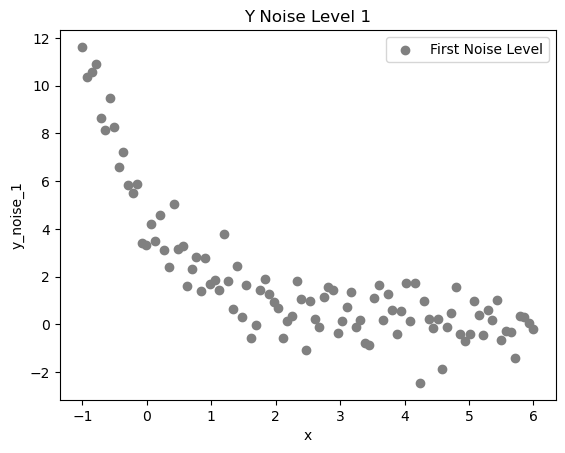

Fit: y = 4.71 * e^(-0.92 * x)


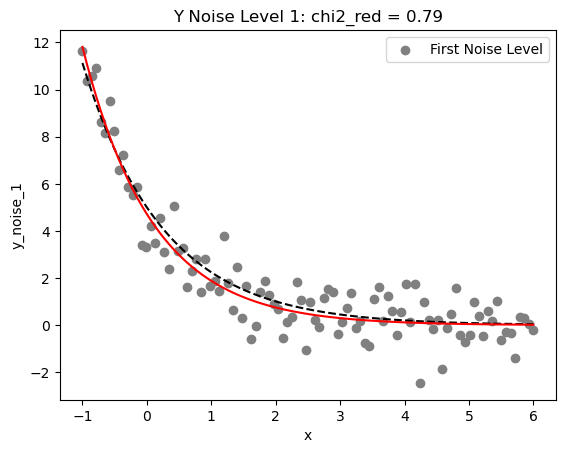

In [37]:
df = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")
print(df.shape)
print(df.head())
print(df.tail())

'''
There are 100 rows and 6 columns, with the columns x, y_noise_1, y_noise_3, y_noise_4, y_noise_5
'''

x = df['x']
y_noise_1 = df['y_noise_1']

plt.figure()
plt.scatter(df['x'], df['y_noise_1'], color = "grey", label = "First Noise Level")
plt.title("Y Noise Level 1")
plt.xlabel("x")
plt.ylabel("y_noise_1")
plt.legend()
plt.show()

def model(x, A, k):
    return A * np.exp(-k * x)

popt, pcov = curve_fit(model, x, y_noise_1, p0=[1,1])
A_fit, k_fit = popt

print(f"Fit: y = {A_fit:.2f} * e^(-{k_fit:.2f} * x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)
chi2_reduced = chi2 / dof

plt.figure()
plt.scatter(df['x'], df['y_noise_1'], color = "grey", label = "First Noise Level")
plt.title(f"Y Noise Level 1: chi2_red = {chi2_reduced:.2f}")
plt.plot(df['x'],model(x, 5, 0.8), color = 'black', ls = '--')
plt.plot(df['x'],model(x, A_fit, k_fit), color = 'red')
plt.xlabel("x")
plt.ylabel("y_noise_1")
plt.legend()
plt.show()

'\nAs the noise increases, the red line is a worse approximation to the black line which makes sense as the data is less accurate. \nThe reduced chi^2 increases as the noise does because this increases the residuals.\n'

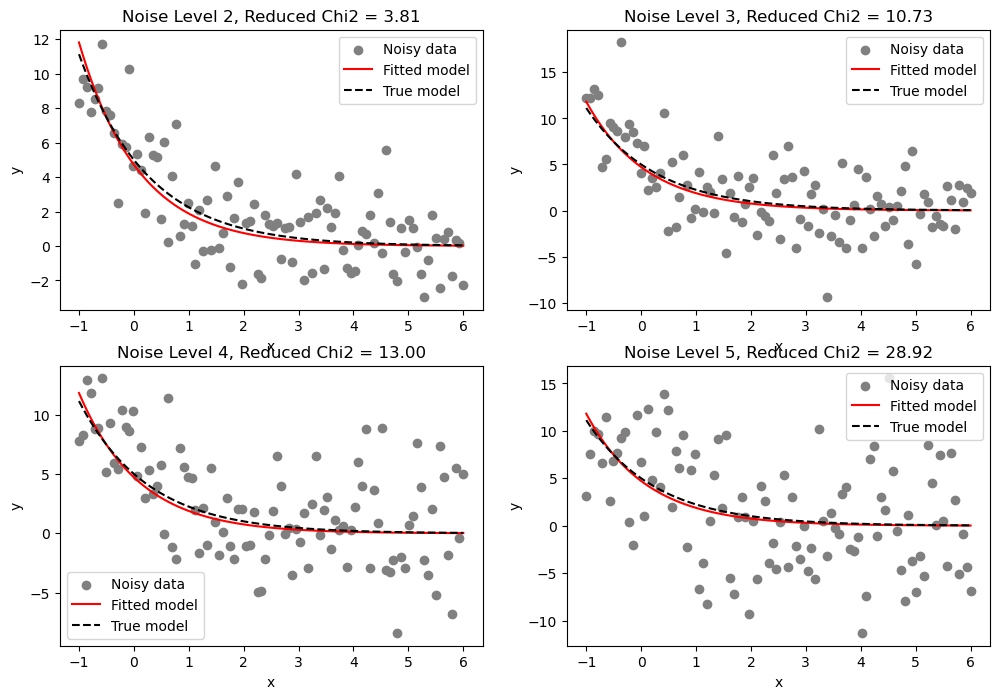

In [38]:
def fit_model(x,y):
    popt, pcov = curve_fit(model, x, y_noise_1, p0=[1,1])
    A_fit, k_fit = popt

    residuals = y - model(x, A_fit, k_fit)
    chi2 = np.sum(residuals**2)
    dof = len(x) - len(popt)
    chi2_reduced = chi2 / dof
    
    return A_fit, k_fit, chi2_reduced

noise = [df["y_noise_2"], df["y_noise_3"], df["y_noise_4"], df["y_noise_5"]]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for i, y in enumerate(noise):

    A_fit, k_fit, chi2_reduced = fit_model(x, y)

    axes[i//2, i%2].scatter(x, y, color="gray", label="Noisy data")
    axes[i//2, i%2].plot(x, model(x, A_fit, k_fit), color="red", label="Fitted model")
    axes[i//2, i%2].plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True model")
   
    axes[i//2, i%2].set_title(f"Noise Level {i+2}, Reduced Chi2 = {chi2_reduced:.2f}")
    axes[i//2, i%2].set_xlabel("x")
    axes[i//2, i%2].set_ylabel("y")
    axes[i//2, i%2].legend()

'''
As the noise increases, the red line is a worse approximation to the black line which makes sense as the data is less accurate. 
The reduced chi^2 increases as the noise does because this increases the residuals.
'''

In [39]:
noise_levels = [1, 2, 3, 4, 5]
noise = [df["y_noise_1"],df["y_noise_2"],df["y_noise_3"],df["y_noise_4"],df["y_noise_5"]]
A_values = []
k_values = []
chi2_values = []

for i, y in enumerate(noise):
    A_fit, k_fit, chi2_reduced = fit_model(x, y)
    A_values.append(A_fit)
    k_values.append(k_fit)
    chi2_values.append(chi2_reduced)

results = {
    "Noise Level": noise_levels,
    "A fit": A_values,
    "k fit": k_values,
    "Reduced chi-squared": chi2_values
}

df = pd.DataFrame(results)
df.to_csv("noisy_parameters.csv", index=False)